In [ ]:
# Model provenance: custom tf.keras.Sequential (not tf.keras.applications.VGG16), include_top not applicable; random init / from scratch.
# Architecture/licence: VGG16-style five convolutional blocks plus 4096/4096 classifier, CC BY 4.0. All layers are trainable; no pretrained or fine-tuned layers.
# Data/training: CIFAR-10 (source: as stated in notebook or unverified), 32x32 RGB, /255 scaling, 45,000 train / 5,000 validation / 10,000 test.
# Adam lr=0.0001, sparse categorical crossentropy, accuracy, batch 64, up to 20 epochs; validation-only checkpointing/early stopping/LR reduction.

In [5]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 2.4 MB/s eta 0:00:0000:0100:08m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 9.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 11.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 14.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━  9/10 [tensorflow]  WARNING: The scripts saved_model_cli, tf_upgrade_v2, tflite_convert and toco are installed in '<runtime-home>/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [tensorflow]0 [tensorflow]
Note: you may need to restart the kernel to use updated packages.


In [5]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.utils import to_categorical

# Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


In [6]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())

# Detect available GPUs
gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs:", gpus)

# Configure GPU memory growth BEFORE GPU initialization
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Memory growth enabled for: {gpu}")
    except RuntimeError as e:
        print("GPU configuration error:", e)

if gpus:
    print("GPU detected. TensorFlow can potentially use the GPU.")
else:
    print("No GPU detected by TensorFlow.")

TensorFlow version: 2.21.0
Built with CUDA: True
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')]
Memory growth enabled for: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Memory growth enabled for: PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
Memory growth enabled for: PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')
GPU detected. TensorFlow can potentially use the GPU.


In [3]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.utils import to_categorical

# Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load the CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

# Verify that the variables exist
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [4]:
plt.imshow(X_train[0])
plt.title(f"Label: {y_train[0][0]}")
plt.axis("off")
plt.show()

NameError: name 'plt' is not defined

In [13]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0
Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)


In [14]:
# Convert labels to one-dimensional arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

print("First 10 labels:", y_train[:10])

Training labels shape: (50000,)
Testing labels shape: (10000,)
First 10 labels: [6 9 9 4 1 1 2 7 8 3]


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=5000,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Testing: (10000, 32, 32, 3) (10000,)


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Create the VGG16 model
model = Sequential(name="VGG16_CIFAR10")

# Input layer
model.add(
    tf.keras.Input(shape=(32, 32, 3))
)

# -------------------------
# BLOCK 1
# -------------------------
model.add(Conv2D(64, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(64, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2), strides=2))

# -------------------------
# BLOCK 2
# -------------------------
model.add(Conv2D(128, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(128, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2), strides=2))

# -------------------------
# BLOCK 3
# -------------------------
model.add(Conv2D(256, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(256, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(256, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2), strides=2))

# -------------------------
# BLOCK 4
# -------------------------
model.add(Conv2D(512, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(512, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(512, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2), strides=2))

# -------------------------
# BLOCK 5
# -------------------------
model.add(Conv2D(512, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(512, (3, 3), activation="relu", padding="same"))
model.add(Conv2D(512, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2), strides=2))

# -------------------------
# CLASSIFICATION HEAD
# -------------------------
model.add(Flatten())

model.add(Dense(4096, activation="relu"))
model.add(Dropout(0.5))

model.add(Dense(4096, activation="relu"))
model.add(Dropout(0.5))

# 10 output classes
model.add(Dense(10, activation="softmax"))

In [17]:
model.summary()

Model: "VGG16_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │     2,101,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        40,970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,638,218 (128.32 MB)

 Trainable params: 33,638,218 (128.32 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Compile the VGG16 model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("VGG16 model compiled successfully!")

VGG16 model compiled successfully!


In [19]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint = ModelCheckpoint(
    "best_vgg16_cifar10.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stop, reduce_lr]

print("Training callbacks configured.")

Training callbacks configured.


In [20]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1790589805.775512   17864 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_43389__.68


702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2537 - loss: 1.8735

I0000 00:00:1790589812.975417   17869 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_43389__.68


704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2539 - loss: 1.8735
Epoch 1: val_accuracy improved from None to 0.37500, saving model to best_vgg16_cifar10.keras

Epoch 1: finished saving model to best_vgg16_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 15ms/step - accuracy: 0.2539 - loss: 1.8735 - val_accuracy: 0.3750 - val_loss: 1.6018 - learning_rate: 1.0000e-04
Epoch 2/20
698/704 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4463 - loss: 1.4627
Epoch 2: val_accuracy improved from 0.37500 to 0.51260, saving model to best_vgg16_cifar10.keras

Epoch 2: finished saving model to best_vgg16_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4469 - loss: 1.4613 - val_accuracy: 0.5126 - val_loss: 1.3382 - learning_rate: 1.0000e-04
Epoch 3/20
697/704 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5583 - loss: 1.2182
Epoch 3: val_accuracy improved from 0.51260 to 0.59080, saving model to best_vgg16_cifar10.keras

Epoch 3: finished saving model to best_vgg16_cifar1

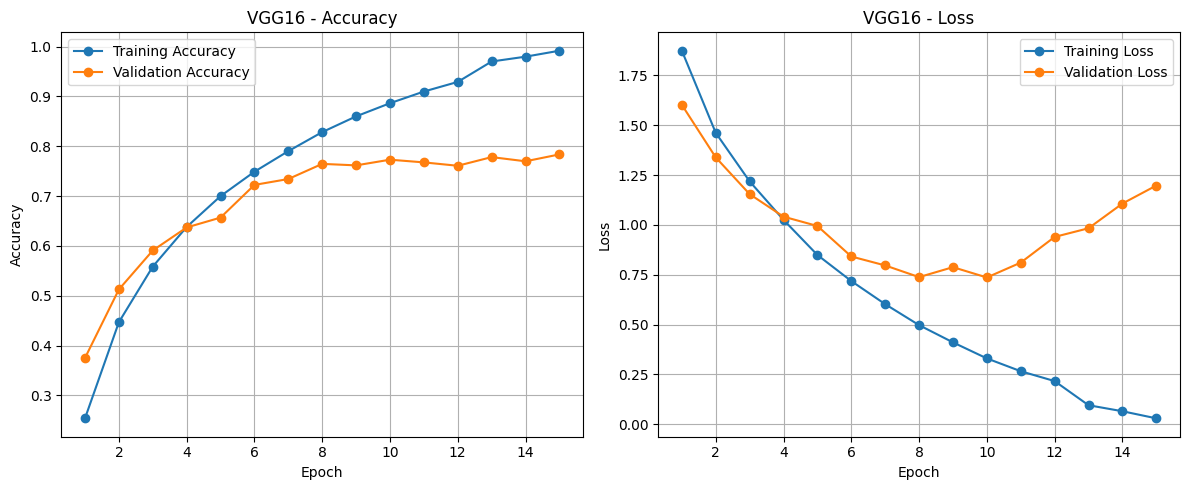

In [21]:
import matplotlib.pyplot as plt

# Extract training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Plot accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, marker="o",
         label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o",
         label="Validation Accuracy")

plt.title("VGG16 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, marker="o",
         label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o",
         label="Validation Loss")

plt.title("VGG16 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.7670 - loss: 0.7792
Test Loss: 0.7792
Test Accuracy: 76.70%


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


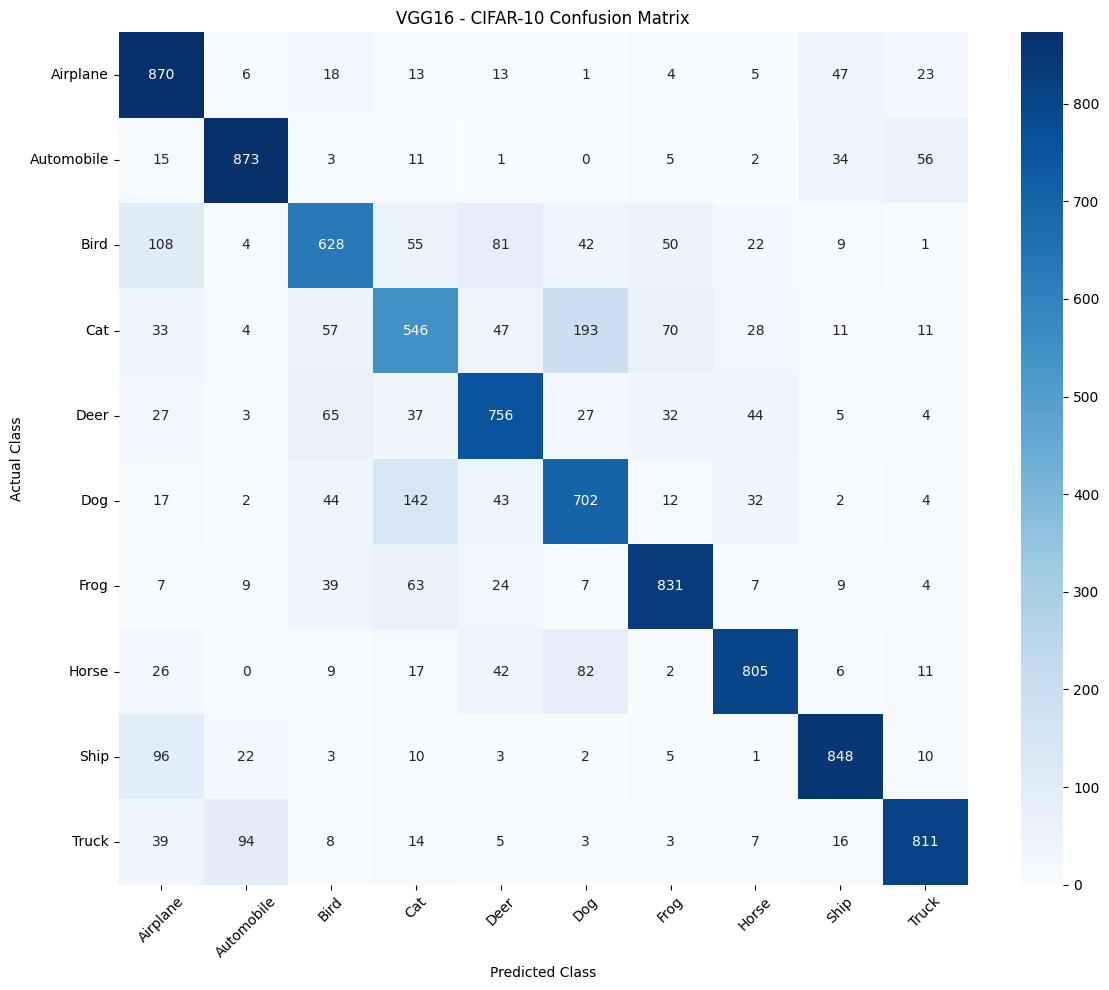

              precision    recall  f1-score   support

    Airplane     0.7027    0.8700    0.7775      1000
  Automobile     0.8584    0.8730    0.8656      1000
        Bird     0.7185    0.6280    0.6702      1000
         Cat     0.6013    0.5460    0.5723      1000
        Deer     0.7448    0.7560    0.7504      1000
         Dog     0.6629    0.7020    0.6819      1000
        Frog     0.8195    0.8310    0.8252      1000
       Horse     0.8447    0.8050    0.8244      1000
        Ship     0.8592    0.8480    0.8535      1000
       Truck     0.8674    0.8110    0.8382      1000

    accuracy                         0.7670     10000
   macro avg     0.7680    0.7670    0.7659     10000
weighted avg     0.7680    0.7670    0.7659     10000



In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Generate predictions for the test dataset
y_pred_prob = model.predict(X_test, batch_size=64, verbose=1)

# Convert predicted probabilities to class indices
y_pred = np.argmax(y_pred_prob, axis=1)

# CIFAR-10 class names
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("VGG16 - CIFAR-10 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print classification report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

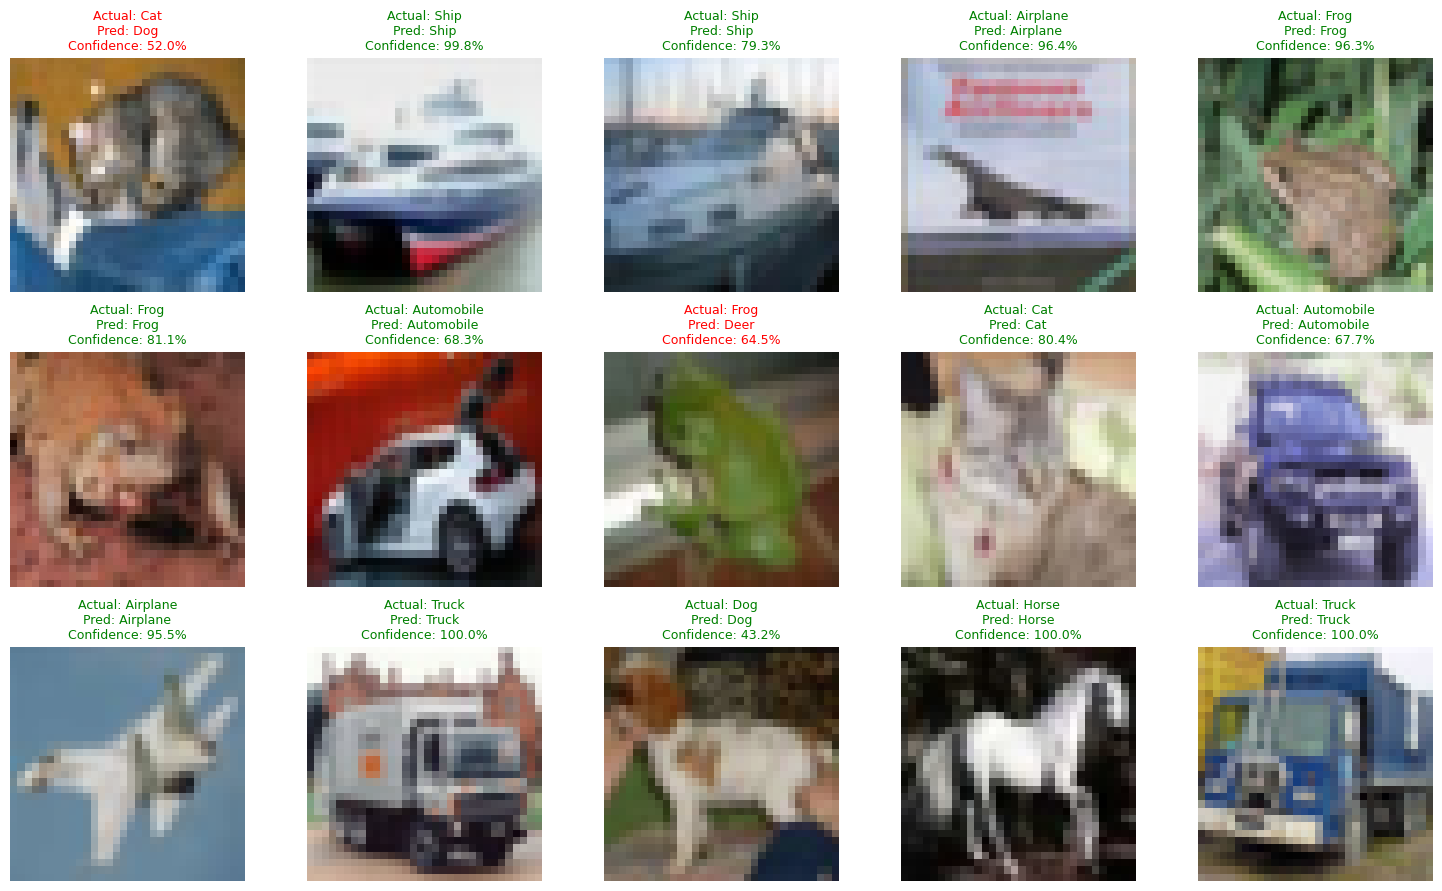

In [24]:
# Display 15 test images with predictions
plt.figure(figsize=(15, 9))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i])

    actual_label = y_test[i]
    predicted_label = y_pred[i]
    confidence = np.max(y_pred_prob[i]) * 100

    color = "green" if actual_label == predicted_label else "red"

    plt.title(
        f"Actual: {class_names[actual_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()